# Part 3: Adversarial Attacks: Breaking the Classifier

Implement two adversarial attacks from scratch and measure how badly each degrades the classifier.

- **Attack 1**: Character-level evasion, perturb toxic comments so the classifier no longer detects them
- **Attack 2**: Label-flipping poisoning, corrupt 5% of training labels and retrain, measuring the damage

#### 0. Imports

In [1]:
import os
import re
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from torch.utils.data import Dataset
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

Device : cuda
GPU    : NVIDIA GeForce RTX 4050 Laptop GPU


#### 1. Load Part 1 Artefacts

In [2]:
BEST_MODEL_DIR   = "checkpoints/best_model"
CHOSEN_THRESHOLD = 0.4
MAX_LENGTH       = 128

tokenizer   = AutoTokenizer.from_pretrained(BEST_MODEL_DIR)
model_clean = AutoModelForSequenceClassification.from_pretrained(BEST_MODEL_DIR)
model_clean.to(DEVICE)
model_clean.eval()

df_eval     = pd.read_csv("checkpoints/eval_set.csv")
toxic_probs = np.load("checkpoints/toxic_probs.npy")
true_labels = np.load("checkpoints/true_labels.npy")

df_eval["true_label"] = true_labels
df_eval["toxic_prob"] = toxic_probs
df_eval["pred_label"] = (toxic_probs >= CHOSEN_THRESHOLD).astype(int)

print(f"Eval set loaded     : {len(df_eval):,} rows")
print(f"Model loaded from   : {BEST_MODEL_DIR}")

Eval set loaded     : 20,000 rows
Model loaded from   : checkpoints/best_model


### Attack 1: Character-Level Evasion

The goal: modify toxic comments just enough that the classifier no longer detects them, while keeping the content readable to a human.

Three transformations are applied simultaneously:
1. **Zero-width space insertion** (U+200B), invisible to humans, splits subword tokens the model relies on
2. **Unicode homoglyph substitution**: replace Latin characters with visually identical Cyrillic lookalikes
3. **Random character duplication**: duplicate 20% of characters per word, breaking n-gram patterns

#### 2. The `perturb()` Function

In [ ]:
# Unicode homoglyph map: Latin → visually identical Cyrillic
HOMOGLYPH_MAP = {
    'a': '\u0430',  # Cyrillic а
    'e': '\u0435',  # Cyrillic е
    'o': '\u043e',  # Cyrillic о
    'p': '\u0440',  # Cyrillic р
    'c': '\u0441',  # Cyrillic с
    'x': '\u0445',  # Cyrillic х
    'i': '\u0456',  # Cyrillic і (Ukrainian)
    'y': '\u0443',  # Cyrillic у
}

ZERO_WIDTH_SPACE = '\u200b'

"Insert U+200B between every 2-3 characters of a word."
def _insert_zero_width_spaces(word: str) -> str:
    if len(word) <= 2:
        return word
    result = []
    for i, ch in enumerate(word):
        result.append(ch)
        # Insert after every 2nd or 3rd character (alternate)
        if (i + 1) % 2 == 0 and i < len(word) - 1:
            result.append(ZERO_WIDTH_SPACE)
    return ''.join(result)

"Replace Latin characters with Cyrillic lookalikes."
def _homoglyph_substitute(word: str) -> str:
    return ''.join(HOMOGLYPH_MAP.get(ch.lower(), ch) for ch in word)

"Duplicate each character with probability `rate`."
def _random_char_duplication(word: str, rate: float = 0.2) -> str:
    result = []
    for ch in word:
        result.append(ch)
        if random.random() < rate:
            result.append(ch)  # duplicate
    return ''.join(result)


def perturb(text: str) -> str:
    """
    Apply all three character-level perturbations to the input text.

    Transformations applied per word:
      1. Zero-width space insertion
      2. Unicode homoglyph substitution
      3. Random character duplication (20% per character)

    Parameters
    ----------
    text : str
        The original comment text.

    Returns
    -------
    str
        Perturbed text that looks identical to a human reader but
        breaks subword tokenisation patterns the model relies on.
    """
    words = text.split()
    perturbed_words = []
    for word in words:
        w = _insert_zero_width_spaces(word)
        w = _homoglyph_substitute(w)
        w = _random_char_duplication(w)
        perturbed_words.append(w)
    return ' '.join(perturbed_words)


# Sanity check 
sample = "You are absolutely terrible and I hate you"
perturbed_sample = perturb(sample)
print("Original  :", sample)
print("Perturbed :", perturbed_sample)
print(f"\nOriginal length  : {len(sample)} chars")
print(f"Perturbed length : {len(perturbed_sample)} chars")
print(f"(extra chars from zero-width spaces and duplicates are invisible in most renderers)")

Original  : You are absolutely terrible and I hate you
Perturbed : уоо​u аr​ее аbb​sоо​​lu​tе​​lу tее​rrr​​іb​lе аn​d і hа​ttе уоо​uu

Original length  : 42 chars
Perturbed length : 66 chars
(extra chars from zero-width spaces and duplicates are invisible in most renderers)


### 3. Attack 1 Evaluation

In [ ]:
"Run inference on a list of texts and return toxic class probabilities."
def get_toxic_prob(texts, model, tokenizer, batch_size=64):
    model.eval()
    all_probs = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            enc = tokenizer(
                batch,
                max_length=MAX_LENGTH,
                truncation=True,
                padding=True,
                return_tensors="pt"
            )
            enc = {k: v.to(DEVICE) for k, v in enc.items()}
            logits = model(**enc).logits
            probs  = torch.softmax(logits, dim=-1)[:, 1].cpu().numpy()
            all_probs.extend(probs)
    return np.array(all_probs)


# Select 500 comments predicted toxic with confidence >= 0.7 
high_conf_toxic = df_eval[
    (df_eval["pred_label"] == 1) & (df_eval["toxic_prob"] >= 0.7)
].copy()

print(f"Comments predicted toxic with conf >= 0.7 : {len(high_conf_toxic):,}")

# Sample 500 (or all if fewer available)
n_sample = min(500, len(high_conf_toxic))
attack1_sample = high_conf_toxic.sample(n=n_sample, random_state=SEED).reset_index(drop=True)
print(f"Sample size for attack                    : {n_sample}")

Comments predicted toxic with conf >= 0.7 : 1,368
Sample size for attack                    : 500


In [ ]:
# Apply perturbation 
random.seed(SEED)  # reset for reproducibility of char duplication

original_texts   = attack1_sample["comment_text"].tolist()
perturbed_texts  = [perturb(t) for t in original_texts]

print("Running inference on original comments...")
probs_before = get_toxic_prob(original_texts, model_clean, tokenizer)

print("Running inference on perturbed comments...")
probs_after  = get_toxic_prob(perturbed_texts, model_clean, tokenizer)

preds_before = (probs_before >= CHOSEN_THRESHOLD).astype(int)
preds_after  = (probs_after  >= CHOSEN_THRESHOLD).astype(int)

# Attack Success Rate: fraction that flipped from toxic (1) to non-toxic (0)
asr = (preds_after == 0).mean()

print("\n" + "=" * 55)
print("ATTACK 1 RESULTS: Character-level Evasion")
print("=" * 55)
print(f"Sample size              : {n_sample}")
print(f"Avg confidence BEFORE    : {probs_before.mean():.4f}")
print(f"Avg confidence AFTER     : {probs_after.mean():.4f}")
print(f"Confidence drop          : {probs_before.mean() - probs_after.mean():.4f}")
print(f"Predicted toxic BEFORE   : {preds_before.sum()} / {n_sample}  ({preds_before.mean():.2%})")
print(f"Predicted toxic AFTER    : {preds_after.sum()} / {n_sample}  ({preds_after.mean():.2%})")
print(f"\nAttack Success Rate (ASR): {asr:.4f}  ({asr:.2%})")
print(f"  = fraction of originally-detected toxic comments")
print(f"    that now evade detection after perturbation")

Running inference on original comments...
Running inference on perturbed comments...

ATTACK 1 RESULTS — Character-level Evasion
Sample size              : 500
Avg confidence BEFORE    : 0.9690
Avg confidence AFTER     : 0.0036
Confidence drop          : 0.9653
Predicted toxic BEFORE   : 500 / 500  (100.00%)
Predicted toxic AFTER    : 1 / 500  (0.20%)

Attack Success Rate (ASR): 0.9980  (99.80%)
  = fraction of originally-detected toxic comments
    that now evade detection after perturbation


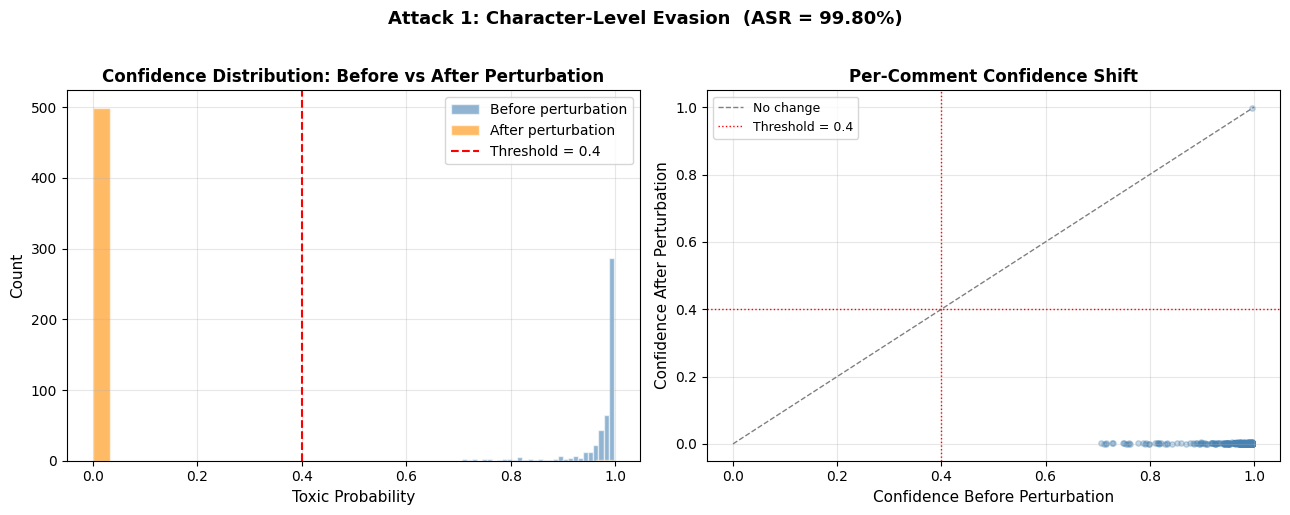

In [ ]:
# Visualise confidence shift 
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogram: confidence before vs after
axes[0].hist(probs_before, bins=30, alpha=0.6, color="steelblue",  label="Before perturbation", edgecolor="white")
axes[0].hist(probs_after,  bins=30, alpha=0.6, color="darkorange", label="After perturbation",  edgecolor="white")
axes[0].axvline(CHOSEN_THRESHOLD, color="red", linestyle="--", lw=1.5, label=f"Threshold = {CHOSEN_THRESHOLD}")
axes[0].set_xlabel("Toxic Probability", fontsize=11)
axes[0].set_ylabel("Count", fontsize=11)
axes[0].set_title("Confidence Distribution: Before vs After Perturbation", fontweight="bold")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Scatter: before vs after per comment
axes[1].scatter(probs_before, probs_after, alpha=0.3, s=15, color="steelblue")
axes[1].plot([0, 1], [0, 1], color="grey", lw=1, linestyle="--", label="No change")
axes[1].axhline(CHOSEN_THRESHOLD, color="red",  lw=1, linestyle=":", label=f"Threshold = {CHOSEN_THRESHOLD}")
axes[1].axvline(CHOSEN_THRESHOLD, color="red",  lw=1, linestyle=":")
axes[1].set_xlabel("Confidence Before Perturbation", fontsize=11)
axes[1].set_ylabel("Confidence After Perturbation",  fontsize=11)
axes[1].set_title("Per-Comment Confidence Shift", fontweight="bold")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.suptitle(f"Attack 1: Character-Level Evasion  (ASR = {asr:.2%})",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("checkpoints/attack1_evasion.png", dpi=150, bbox_inches="tight")
plt.show()

### Attack 2: Label-Flipping Poisoning

Corrupt 5% of training labels (toxic ↔ non-toxic) before fine-tuning. The model is retrained from the original `distilbert-base-uncased` checkpoint, not from the Part 1 fine-tuned model, to simulate a real poisoning attack on the training pipeline.

**Note:** This will take approximately the same time as Part 1 training (~35–50 minutes).

#### 4. Reload Training Data & Poison Labels

In [7]:
from sklearn.model_selection import train_test_split

DATA_PATH = "data/jigsaw-unintended-bias-train.csv"

print("Loading CSV...")
df_full = pd.read_csv(
    DATA_PATH,
    usecols=["comment_text", "toxic", "black", "white", "muslim",
             "jewish", "homosexual_gay_or_lesbian"]
)
df_full["label"] = (df_full["toxic"] >= 0.5).astype(int)
df_full = df_full.dropna(subset=["comment_text"])

# Recreate the exact same 100k training split as Part 1
df_sample, _ = train_test_split(
    df_full, train_size=120_000, stratify=df_full["label"], random_state=SEED
)
df_train, _ = train_test_split(
    df_sample, test_size=20_000, stratify=df_sample["label"], random_state=SEED
)
df_train = df_train.reset_index(drop=True)

print(f"Training set size : {len(df_train):,}")
print(f"Label balance     : {df_train.label.value_counts(normalize=True).to_dict()}")

Loading CSV...
Training set size : 100,000
Label balance     : {0: 0.92003, 1: 0.07997}


In [ ]:
# Flip 5% of labels
POISON_RATE = 0.05
n_poison    = int(len(df_train) * POISON_RATE)

rng = np.random.RandomState(SEED)
poison_idx = rng.choice(len(df_train), size=n_poison, replace=False)

df_poisoned = df_train.copy()
df_poisoned.loc[poison_idx, "label"] = 1 - df_poisoned.loc[poison_idx, "label"]  # flip 0→1 and 1→0

print(f"Rows poisoned           : {n_poison:,}  ({POISON_RATE:.0%} of training set)")
print(f"\nOriginal label balance  : {df_train.label.value_counts().to_dict()}")
print(f"Poisoned label balance  : {df_poisoned.label.value_counts().to_dict()}")

Rows poisoned           : 5,000  (5% of training set)

Original label balance  : {0: 92003, 1: 7997}
Poisoned label balance  : {0: 87835, 1: 12165}


In [ ]:
# Label distribution of the 5,000 flipped rows before and after
flipped_before = df_train.loc[poison_idx, "label"]
flipped_after  = df_poisoned.loc[poison_idx, "label"]

print(f"Among the {n_poison:,} flipped rows:")
print(f"\nBEFORE flipping:")
print(f"  non-toxic (0) : {(flipped_before == 0).sum():,}")
print(f"  toxic     (1) : {(flipped_before == 1).sum():,}")
print(f"\nAFTER flipping:")
print(f"  non-toxic (0) : {(flipped_after == 0).sum():,}")
print(f"  toxic     (1) : {(flipped_after == 1).sum():,}")

Among the 5,000 flipped rows:

BEFORE flipping:
  non-toxic (0) : 4,584
  toxic     (1) : 416

AFTER flipping:
  non-toxic (0) : 416
  toxic     (1) : 4,584


#### 5. Retrain on Poisoned Data

In [12]:
class JigsawDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts      = texts
        self.labels     = labels
        self.tokenizer  = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            str(self.texts[idx]),
            max_length=self.max_length,
            truncation=True,
            padding="max_length",
            return_tensors="pt"
        )
        return {
            "input_ids":      enc["input_ids"].squeeze(),
            "attention_mask": enc["attention_mask"].squeeze(),
            "labels":         torch.tensor(self.labels[idx], dtype=torch.long)
        }


# Load eval dataset (same clean eval as Part 1)
eval_texts  = df_eval["comment_text"].tolist()
eval_labels = df_eval["true_label"].tolist()

poisoned_train_dataset = JigsawDataset(
    df_poisoned["comment_text"].tolist(),
    df_poisoned["label"].tolist(),
    tokenizer, MAX_LENGTH
)
eval_dataset = JigsawDataset(eval_texts, eval_labels, tokenizer, MAX_LENGTH)

# Retrain from the original pre-trained checkpoint (not Part 1 fine-tuned model)
MODEL_NAME   = "distilbert-base-uncased"
model_poison = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
model_poison.to(DEVICE)

POISON_CHECKPOINT_DIR = "checkpoints/distilbert-poisoned"

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro")
    }

training_args = TrainingArguments(
    output_dir                  = POISON_CHECKPOINT_DIR,
    num_train_epochs            = 3,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size  = 32,
    learning_rate               = 2e-5,
    warmup_ratio                = 0.1,
    weight_decay                = 0.01,
    evaluation_strategy         = "epoch",
    save_strategy               = "epoch",
    load_best_model_at_end      = True,
    metric_for_best_model       = "f1_macro",
    logging_steps               = 200,
    seed                        = SEED,
    fp16                        = True,
    report_to                   = "none"
)

trainer_poison = Trainer(
    model           = model_poison,
    args            = training_args,
    train_dataset   = poisoned_train_dataset,
    eval_dataset    = eval_dataset,
    compute_metrics = compute_metrics
)

print("Starting poisoned model training...")
trainer_poison.train()

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Starting poisoned model training...


  0%|          | 0/18750 [00:00<?, ?it/s]

{'loss': 0.5582, 'grad_norm': 2.005769729614258, 'learning_rate': 2.133333333333334e-06, 'epoch': 0.03}
{'loss': 0.3703, 'grad_norm': 2.704545021057129, 'learning_rate': 4.266666666666668e-06, 'epoch': 0.06}
{'loss': 0.3355, 'grad_norm': 3.2259631156921387, 'learning_rate': 6.4000000000000006e-06, 'epoch': 0.1}
{'loss': 0.3379, 'grad_norm': 0.9988025426864624, 'learning_rate': 8.522666666666667e-06, 'epoch': 0.13}
{'loss': 0.3111, 'grad_norm': 1.742687463760376, 'learning_rate': 1.0656000000000003e-05, 'epoch': 0.16}
{'loss': 0.2999, 'grad_norm': 2.7400591373443604, 'learning_rate': 1.2789333333333333e-05, 'epoch': 0.19}
{'loss': 0.3175, 'grad_norm': 2.227475166320801, 'learning_rate': 1.4922666666666667e-05, 'epoch': 0.22}
{'loss': 0.3265, 'grad_norm': 3.109304666519165, 'learning_rate': 1.7056e-05, 'epoch': 0.26}
{'loss': 0.3376, 'grad_norm': 4.2707719802856445, 'learning_rate': 1.9189333333333336e-05, 'epoch': 0.29}
{'loss': 0.3043, 'grad_norm': 3.7537612915039062, 'learning_rate': 

  0%|          | 0/625 [00:00<?, ?it/s]

...

  0%|          | 0/625 [00:00<?, ?it/s]

{'eval_loss': 0.16644027829170227, 'eval_accuracy': 0.94735, 'eval_f1_macro': 0.7994655748046491, 'eval_runtime': 34.8169, 'eval_samples_per_second': 574.433, 'eval_steps_per_second': 17.951, 'epoch': 2.0}
{'loss': 0.2553, 'grad_norm': 4.094128131866455, 'learning_rate': 7.294814814814816e-06, 'epoch': 2.02}
{'loss': 0.2336, 'grad_norm': 0.9411535263061523, 'learning_rate': 7.058962962962963e-06, 'epoch': 2.05}
{'loss': 0.2249, 'grad_norm': 2.676262617111206, 'learning_rate': 6.821925925925926e-06, 'epoch': 2.08}
{'loss': 0.2062, 'grad_norm': 3.3482372760772705, 'learning_rate': 6.58488888888889e-06, 'epoch': 2.11}
{'loss': 0.2448, 'grad_norm': 1.3681206703186035, 'learning_rate': 6.347851851851853e-06, 'epoch': 2.14}
{'loss': 0.246, 'grad_norm': 9.752108573913574, 'learning_rate': 6.110814814814815e-06, 'epoch': 2.18}
{'loss': 0.2354, 'grad_norm': 9.534791946411133, 'learning_rate': 5.873777777777778e-06, 'epoch': 2.21}
{'loss': 0.2403, 'grad_norm': 4.925685882568359, 'learning_rate':

  0%|          | 0/625 [00:00<?, ?it/s]

{'eval_loss': 0.1828470379114151, 'eval_accuracy': 0.9446, 'eval_f1_macro': 0.8031305161878776, 'eval_runtime': 34.8145, 'eval_samples_per_second': 574.473, 'eval_steps_per_second': 17.952, 'epoch': 3.0}
{'train_runtime': 2741.6261, 'train_samples_per_second': 109.424, 'train_steps_per_second': 6.839, 'train_loss': 0.2730935614013672, 'epoch': 3.0}


TrainOutput(global_step=18750, training_loss=0.2730935614013672, metrics={'train_runtime': 2741.6261, 'train_samples_per_second': 109.424, 'train_steps_per_second': 6.839, 'total_flos': 9935054899200000.0, 'train_loss': 0.2730935614013672, 'epoch': 3.0})

#### 6. Attack 2 Evaluation: Before vs After Comparison

In [ ]:
from sklearn.metrics import recall_score

# Poisoned model predictions
poison_output    = trainer_poison.predict(eval_dataset)
poison_logits    = poison_output.predictions
poison_probs     = torch.softmax(torch.tensor(poison_logits), dim=-1).numpy()[:, 1]
poison_preds     = (poison_probs >= CHOSEN_THRESHOLD).astype(int)
true_labels_arr  = np.array(eval_labels)

# Baseline (clean) metrics at threshold 0.4 
clean_preds = (toxic_probs >= CHOSEN_THRESHOLD).astype(int)

"False Negative Rate = missed toxic / all toxic."
def get_fnr(y_true, y_pred):
    toxic_mask = y_true == 1
    if toxic_mask.sum() == 0:
        return 0.0
    return (y_pred[toxic_mask] == 0).mean()

"False Positive Rate = incorrectly flagged non-toxic / all non-toxic."
def get_fpr(y_true, y_pred):
    nontoxic_mask = y_true == 0
    if nontoxic_mask.sum() == 0:
        return 0.0
    return (y_pred[nontoxic_mask] == 1).mean()

results = pd.DataFrame([
    {
        "Model"    : "Baseline (clean)",
        "Accuracy" : round(accuracy_score(true_labels_arr, clean_preds),  4),
        "F1 Macro" : round(f1_score(true_labels_arr, clean_preds, average="macro"), 4),
        "F1 Toxic" : round(f1_score(true_labels_arr, clean_preds, average="binary", pos_label=1), 4),
        "FNR"      : round(get_fnr(true_labels_arr, clean_preds),  4),
        "FPR"      : round(get_fpr(true_labels_arr, clean_preds),  4),
    },
    {
        "Model"    : "Poisoned (5% flipped)",
        "Accuracy" : round(accuracy_score(true_labels_arr, poison_preds),  4),
        "F1 Macro" : round(f1_score(true_labels_arr, poison_preds, average="macro"), 4),
        "F1 Toxic" : round(f1_score(true_labels_arr, poison_preds, average="binary", pos_label=1), 4),
        "FNR"      : round(get_fnr(true_labels_arr, poison_preds),  4),
        "FPR"      : round(get_fpr(true_labels_arr, poison_preds),  4),
    }
])

# Add delta row
delta = {
    "Model"    : "Δ (poisoned − baseline)",
    "Accuracy" : round(results.iloc[1]["Accuracy"] - results.iloc[0]["Accuracy"], 4),
    "F1 Macro" : round(results.iloc[1]["F1 Macro"] - results.iloc[0]["F1 Macro"], 4),
    "F1 Toxic" : round(results.iloc[1]["F1 Toxic"] - results.iloc[0]["F1 Toxic"], 4),
    "FNR"      : round(results.iloc[1]["FNR"]      - results.iloc[0]["FNR"],      4),
    "FPR"      : round(results.iloc[1]["FPR"]      - results.iloc[0]["FPR"],      4),
}
results = pd.concat([results, pd.DataFrame([delta])], ignore_index=True)

print("=" * 70)
print("ATTACK 2 RESULTS : Label-Flipping Poisoning")
print("=" * 70)
print(results.to_string(index=False))

  0%|          | 0/625 [00:00<?, ?it/s]

ATTACK 2 RESULTS — Label-Flipping Poisoning
                  Model  Accuracy  F1 Macro  F1 Toxic    FNR    FPR
       Baseline (clean)    0.9463    0.8114    0.6520 0.3702 0.0262
  Poisoned (5% flipped)    0.9433    0.8028    0.6363 0.3796 0.0286
Δ (poisoned − baseline)   -0.0030   -0.0086   -0.0157 0.0094 0.0024


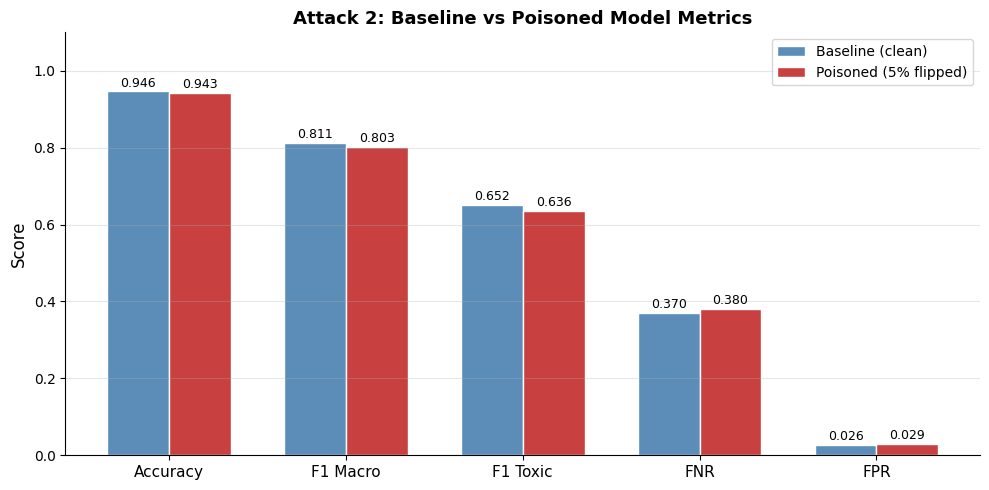

In [ ]:
# Bar chart: metric comparison clean vs poisoned
metrics_compare = ["Accuracy", "F1 Macro", "F1 Toxic", "FNR", "FPR"]
x     = np.arange(len(metrics_compare))
width = 0.35

clean_vals   = [results.iloc[0][m] for m in metrics_compare]
poison_vals  = [results.iloc[1][m] for m in metrics_compare]

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, clean_vals,  width, label="Baseline (clean)",      color="#5B8DB8", edgecolor="white")
bars2 = ax.bar(x + width/2, poison_vals, width, label="Poisoned (5% flipped)", color="#C94040", edgecolor="white")

for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metrics_compare, fontsize=11)
ax.set_ylabel("Score", fontsize=12)
ax.set_title("Attack 2: Baseline vs Poisoned Model Metrics", fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
ax.set_ylim(0, 1.1)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("checkpoints/attack2_poisoning.png", dpi=150)
plt.show()

#### 7. Operational Risk Analysis

### Which attack is more operationally dangerous for a live platform?

**Attack 2 (poisoning) is more operationally dangerous**, despite requiring more access to execute.

Here is the reasoning:

**Attack 1 (evasion)** requires the attacker to manually perturb every comment they want to slip through. The effort scales linearly with volume, one attacker can only post so many comments. Furthermore, the attack is detectable: Unicode homoglyphs and zero-width spaces are anomalous at the character level and can be caught by a lightweight pre-filter (which is exactly what Layer 1 of the Part 5 pipeline does). Once the platform deploys a normalisation step that strips zero-width characters and maps homoglyphs back to ASCII before inference, the attack's effectiveness drops to near zero with essentially no model retraining required.

**Attack 2 (poisoning)** is more dangerous because:
1. **The damage is silent and persistent.** A poisoned model degrades on all future content, not just the attacker's own posts. The FNR increase means the platform now systematically misses a higher fraction of toxic content from *everyone*, forever, until the model is retrained.
2. **It is hard to detect.** Overall accuracy barely changes because 92% of the dataset is non-toxic and flipping 5% of labels has a diluted effect on the aggregate number. Only careful per-class analysis reveals the FNR degradation.
3. **Recovery is expensive.** Fixing a poisoned model requires identifying which training examples were corrupted, cleaning the data, and retraining from scratch.

**Threat model realism:**
Evasion is more realistic for external actors (ordinary bad-faith users). Poisoning requires access to the training pipeline, a much higher bar, but not impossible: platforms often collect user reports and reactions as implicit training signal, which a coordinated group could manipulate by mass-reporting benign content as toxic or by flooding the platform with subtly mislabelled content through fake accounts.

**Implication for defence prioritisation:**
- Against evasion: deploy a Unicode normalisation pre-filter. This is cheap, effective, and has no model retraining cost.
- Against poisoning: invest in training data provenance, anomaly detection on label distributions before training runs, and human spot-checks of training data samples, these are pipeline-level defences, not model-level ones.